In [1]:
#importing important libraries..
!pip install catboost
!pip install imblearn

import warnings, time
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import gc, os
from sklearn.model_selection import StratifiedKFold, cross_validate, GridSearchCV, train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.feature_selection import mutual_info_classif

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE

import xgboost as xgb
import lightgbm as lgb
from catboost import CatBoostClassifier

from sklearn.ensemble import HistGradientBoostingClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.ensemble import EasyEnsembleClassifier


# Display Options
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

# Plot Style
plt.style.use("ggplot")

sns.set_style("whitegrid")
plt.rcParams.update({"figure.dpi": 120, "savefig.dpi": 300, "font.size": 11})
SEED = 42
np.random.seed(SEED)
print("Environment ready")


[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 25.2 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


Environment ready


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [2]:
data = pd.read_csv("Dataset.csv")
label = pd.read_csv("Label.csv")
print(data.shape, label.shape)
print(len(data), len(label))
print(len(data) == len(label))


(447915, 76) (447915, 1)
447915 447915
True


# Basic data analysis..

In [4]:
print("Dataset shape:", data.shape)
print("Label shape:", label.shape)

print("\nDataset columns:")
print(data.columns.tolist())

print("\nDataset dtypes:")
print(data.dtypes)

print("\nFirst 5 rows of Dataset:")
display(data.head())

print("\nFirst 5 rows of Label:")
display(label.head())

Dataset shape: (447915, 76)
Label shape: (447915, 1)

Dataset columns:
['Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Fla

,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min
0,214392,9,21,388.0,24564.0,194.0,0.0,43.111111,85.545959,1460.0,0.0,1169.714286,552.156965,116384.939737,139.930594,7392.827586,17881.622845,61855.0,2.0,213501.0,26687.625000,35191.916072,87999.0,10.0,207850.0,10392.5,3.826029e+04,168673.0,2.0,0,0,0,0,212,436,41.979178,97.951416,0.0,1460.0,804.903226,702.892469,494057.823656,2,4,0,2,28,0,0,0,2.0,831.733333,43.111111,1169.714286,0,0,0,24952,20,402393,0,0,0,0,16383,16383,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,2376792,9,3,752.0,0.0,188.0,0.0,83.555556,99.084700,0.0,0.0,0.000000,0.000000,316.392852,5.048822,216072.000000,638179.872769,2138664.0,11.0,2323484.0,290435.500000,747410.857535,2138664.0,11.0,2357699.0,1178849.5,1.667118e+06,2357680.0,19.0,0,0,0,0,212,76,3.786617,1.262206,0.0,188.0,57.846154,90.312279,8156.307692,2,4,0,0,10,0,0,0,0.0,62.666667,83.555556,0.000000,0,0,0,0,0,0,9,752,3,0,16383,16383,4,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,131350,10,3,7564.0,0.0,1460.0,0.0,756.400000,690.497277,0.0,0.0,0.000000,0.000000,57586.600685,98.972212,10945.833333,21066.252205,62942.0,2.0,119039.0,13226.555556,25983.491245,62942.0,2.0,122595.0,61297.5,8.667503e+04,122586.0,9.0,0,0,0,0,232,76,76.132470,22.839741,0.0,1460.0,540.285714,675.150516,455828.219780,1,4,0,0,11,0,0,0,0.0,581.846154,756.400000,0.000000,0,0,0,7564,6,6367003,0,0,0,0,16383,16383,6,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,164796,6,3,770.0,0.0,385.0,0.0,128.333333,198.813145,0.0,0.0,0.000000,0.000000,4672.443506,54.612976,20599.500000,26851.824918,59363.0,11.0,111397.0,22279.400000,30599.330537,59363.0,11.0,157703.0,78851.5,1.114959e+05,157691.0,12.0,0,0,0,0,152,76,36.408651,18.204325,0.0,385.0,77.000000,162.330253,26351.111111,1,4,0,0,7,0,0,0,0.0,85.555556,128.333333,0.000000,0,0,0,0,0,0,0,0,0,0,16383,16383,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,163418,6,3,400.0,0.0,200.0,0.0,66.666667,103.279556,0.0,0.0,0.000000,0.000000,2447.710778,55.073493,20427.250000,27063.749406,62193.0,11.0,112374.0,22474.800000,31050.388568,62193.0,11.0,157512.0,78756.0,1.113594e+05,157499.0,13.0,0,0,0,0,152,76,36.715662,18.357831,0.0,200.0,40.000000,84.327404,7111.111111,1,4,0,0,7,0,0,0,0.0,44.444444,66.666667,0.000000,0,0,0,0,0,0,0,0,0,0,16383,16383,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0



First 5 rows of Label:


,Label
0,4
1,7
2,4
3,3
4,6


In [24]:
print("Unique labels:")
print(label.iloc[:, 0].unique())

print("\nNumber of unique classes:")
print(label.iloc[:, 0].nunique())

print("\nClass counts:")

print(label.iloc[:, 0].value_counts())

print("\nClass percentages:")
print((label.iloc[:, 0].value_counts(normalize=True) * 100).round(4))

Unique labels:
[4 7 3 6 0 8 5 9 2 1]

Number of unique classes:
10

Class counts:
Label
0    358332
4     30951
5     29613
7     16735
6      4632
3      4467
8      2102
2       452
1       385
9       246
Name: count, dtype: int64

Class percentages:
Label
0    80.0000
4     6.9100
5     6.6113
7     3.7362
6     1.0341
3     0.9973
8     0.4693
2     0.1009
1     0.0860
9     0.0549
Name: proportion, dtype: float64


# Merging the datasets with lable...

In [5]:


l = label.iloc[:, 0].copy()
l.name = "Label"

df = pd.concat([data, l], axis=1)

print("Final shape:", df.shape)
display(df.head())

Final shape: (447915, 77)


,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label
0,214392,9,21,388.0,24564.0,194.0,0.0,43.111111,85.545959,1460.0,0.0,1169.714286,552.156965,116384.939737,139.930594,7392.827586,17881.622845,61855.0,2.0,213501.0,26687.625000,35191.916072,87999.0,10.0,207850.0,10392.5,3.826029e+04,168673.0,2.0,0,0,0,0,212,436,41.979178,97.951416,0.0,1460.0,804.903226,702.892469,494057.823656,2,4,0,2,28,0,0,0,2.0,831.733333,43.111111,1169.714286,0,0,0,24952,20,402393,0,0,0,0,16383,16383,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4
1,2376792,9,3,752.0,0.0,188.0,0.0,83.555556,99.084700,0.0,0.0,0.000000,0.000000,316.392852,5.048822,216072.000000,638179.872769,2138664.0,11.0,2323484.0,290435.500000,747410.857535,2138664.0,11.0,2357699.0,1178849.5,1.667118e+06,2357680.0,19.0,0,0,0,0,212,76,3.786617,1.262206,0.0,188.0,57.846154,90.312279,8156.307692,2,4,0,0,10,0,0,0,0.0,62.666667,83.555556,0.000000,0,0,0,0,0,0,9,752,3,0,16383,16383,4,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,7
2,131350,10,3,7564.0,0.0,1460.0,0.0,756.400000,690.497277,0.0,0.0,0.000000,0.000000,57586.600685,98.972212,10945.833333,21066.252205,62942.0,2.0,119039.0,13226.555556,25983.491245,62942.0,2.0,122595.0,61297.5,8.667503e+04,122586.0,9.0,0,0,0,0,232,76,76.132470,22.839741,0.0,1460.0,540.285714,675.150516,455828.219780,1,4,0,0,11,0,0,0,0.0,581.846154,756.400000,0.000000,0,0,0,7564,6,6367003,0,0,0,0,16383,16383,6,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,4
3,164796,6,3,770.0,0.0,385.0,0.0,128.333333,198.813145,0.0,0.0,0.000000,0.000000,4672.443506,54.612976,20599.500000,26851.824918,59363.0,11.0,111397.0,22279.400000,30599.330537,59363.0,11.0,157703.0,78851.5,1.114959e+05,157691.0,12.0,0,0,0,0,152,76,36.408651,18.204325,0.0,385.0,77.000000,162.330253,26351.111111,1,4,0,0,7,0,0,0,0.0,85.555556,128.333333,0.000000,0,0,0,0,0,0,0,0,0,0,16383,16383,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,3
4,163418,6,3,400.0,0.0,200.0,0.0,66.666667,103.279556,0.0,0.0,0.000000,0.000000,2447.710778,55.073493,20427.250000,27063.749406,62193.0,11.0,112374.0,22474.800000,31050.388568,62193.0,11.0,157512.0,78756.0,1.113594e+05,157499.0,13.0,0,0,0,0,152,76,36.715662,18.357831,0.0,200.0,40.000000,84.327404,7111.111111,1,4,0,0,7,0,0,0,0.0,44.444444,66.666667,0.000000,0,0,0,0,0,0,0,0,0,0,16383,16383,2,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6


In [7]:
m_df = pd.read_csv("merged_dataset.csv")
print(m_df.shape)
print(m_df.head(5).T)

(447915, 77)
                                        0             1             2  \
Flow Duration               214392.000000  2.376792e+06  1.313500e+05   
Total Fwd Packet                 9.000000  9.000000e+00  1.000000e+01   
Total Bwd packets               21.000000  3.000000e+00  3.000000e+00   
Total Length of Fwd Packet     388.000000  7.520000e+02  7.564000e+03   
Total Length of Bwd Packet   24564.000000  0.000000e+00  0.000000e+00   
Fwd Packet Length Max          194.000000  1.880000e+02  1.460000e+03   
Fwd Packet Length Min            0.000000  0.000000e+00  0.000000e+00   
Fwd Packet Length Mean          43.111111  8.355556e+01  7.564000e+02   
Fwd Packet Length Std           85.545959  9.908470e+01  6.904973e+02   
Bwd Packet Length Max         1460.000000  0.000000e+00  0.000000e+00   
Bwd Packet Length Min            0.000000  0.000000e+00  0.000000e+00   
Bwd Packet Length Mean        1169.714286  0.000000e+00  0.000000e+00   
Bwd Packet Length Std          552.156

In [26]:
print("Total rows:", len(df))
print("Total columns:", len(df.columns))

print("\nData types:")
print(df.dtypes.value_counts())

print("\nMissing values:")
missing = df.isnull().sum()
print(missing[missing > 0].sort_values(ascending=False))

print("\nDuplicate rows:", df.duplicated().sum())

print("\nDuplicate feature rows:")
print(df.drop(columns="Label").duplicated().sum())

Total rows: 447915
Total columns: 77

Data types:
float64    45
int64      32
Name: count, dtype: int64

Missing values:
Series([], dtype: int64)

Duplicate rows: 141742

Duplicate feature rows:
142313


I had found duplicated rows and feature rows. Than I run several investigations to find out what kind of duplicate they are and finally removing the duplicates that won't effect the genuinity of the dataset.

In [27]:
# ==========================================
# DUPLICATE HANDLING
# ==========================================

print("Before duplicate removal:")
print("Rows:", len(df))
l_df = len(df)

df = (
    df
    .drop_duplicates()
    .reset_index(drop=True)
)

print("\nAfter duplicate removal:")
print("Rows:", len(df))

print("\nRows removed:", l_df - len(df))

print(
    "Percentage removed:",
    round((l_df - len(df)) / l_df * 100, 2),
    "%"
)

Before duplicate removal:
Rows: 447915

After duplicate removal:
Rows: 306173

Rows removed: 141742
Percentage removed: 31.64 %


In [28]:
print("Clean dataset shape:", df.shape)

print("\nExact duplicates remaining:")
print(df.duplicated().sum())

print("\nFeature duplicates remaining:")
print(
    df.drop(columns="Label").duplicated().sum()
)
print(np.isinf(df.select_dtypes(include=np.number)).sum().sum())


Clean dataset shape: (306173, 77)

Exact duplicates remaining:
0

Feature duplicates remaining:
571
0


# Data Visualization

Mapping the label column for data visualization..
The mapping dictionary has been collected from the official Readme file of the dataset.

In [29]:
label_map = {
    0 : "Benign",
    1 : "Analysis",
    2 : "Backdoor",
    3 : "DoS",
    4 : "Exploits",
    5 : "Fuzzers",
    6 : "Generic",
    7 : "Reconnaissance",
    8 : "Shellcode",
    9 : "Worms"
}
df["Label_mapped"] = df["Label"].map(label_map)

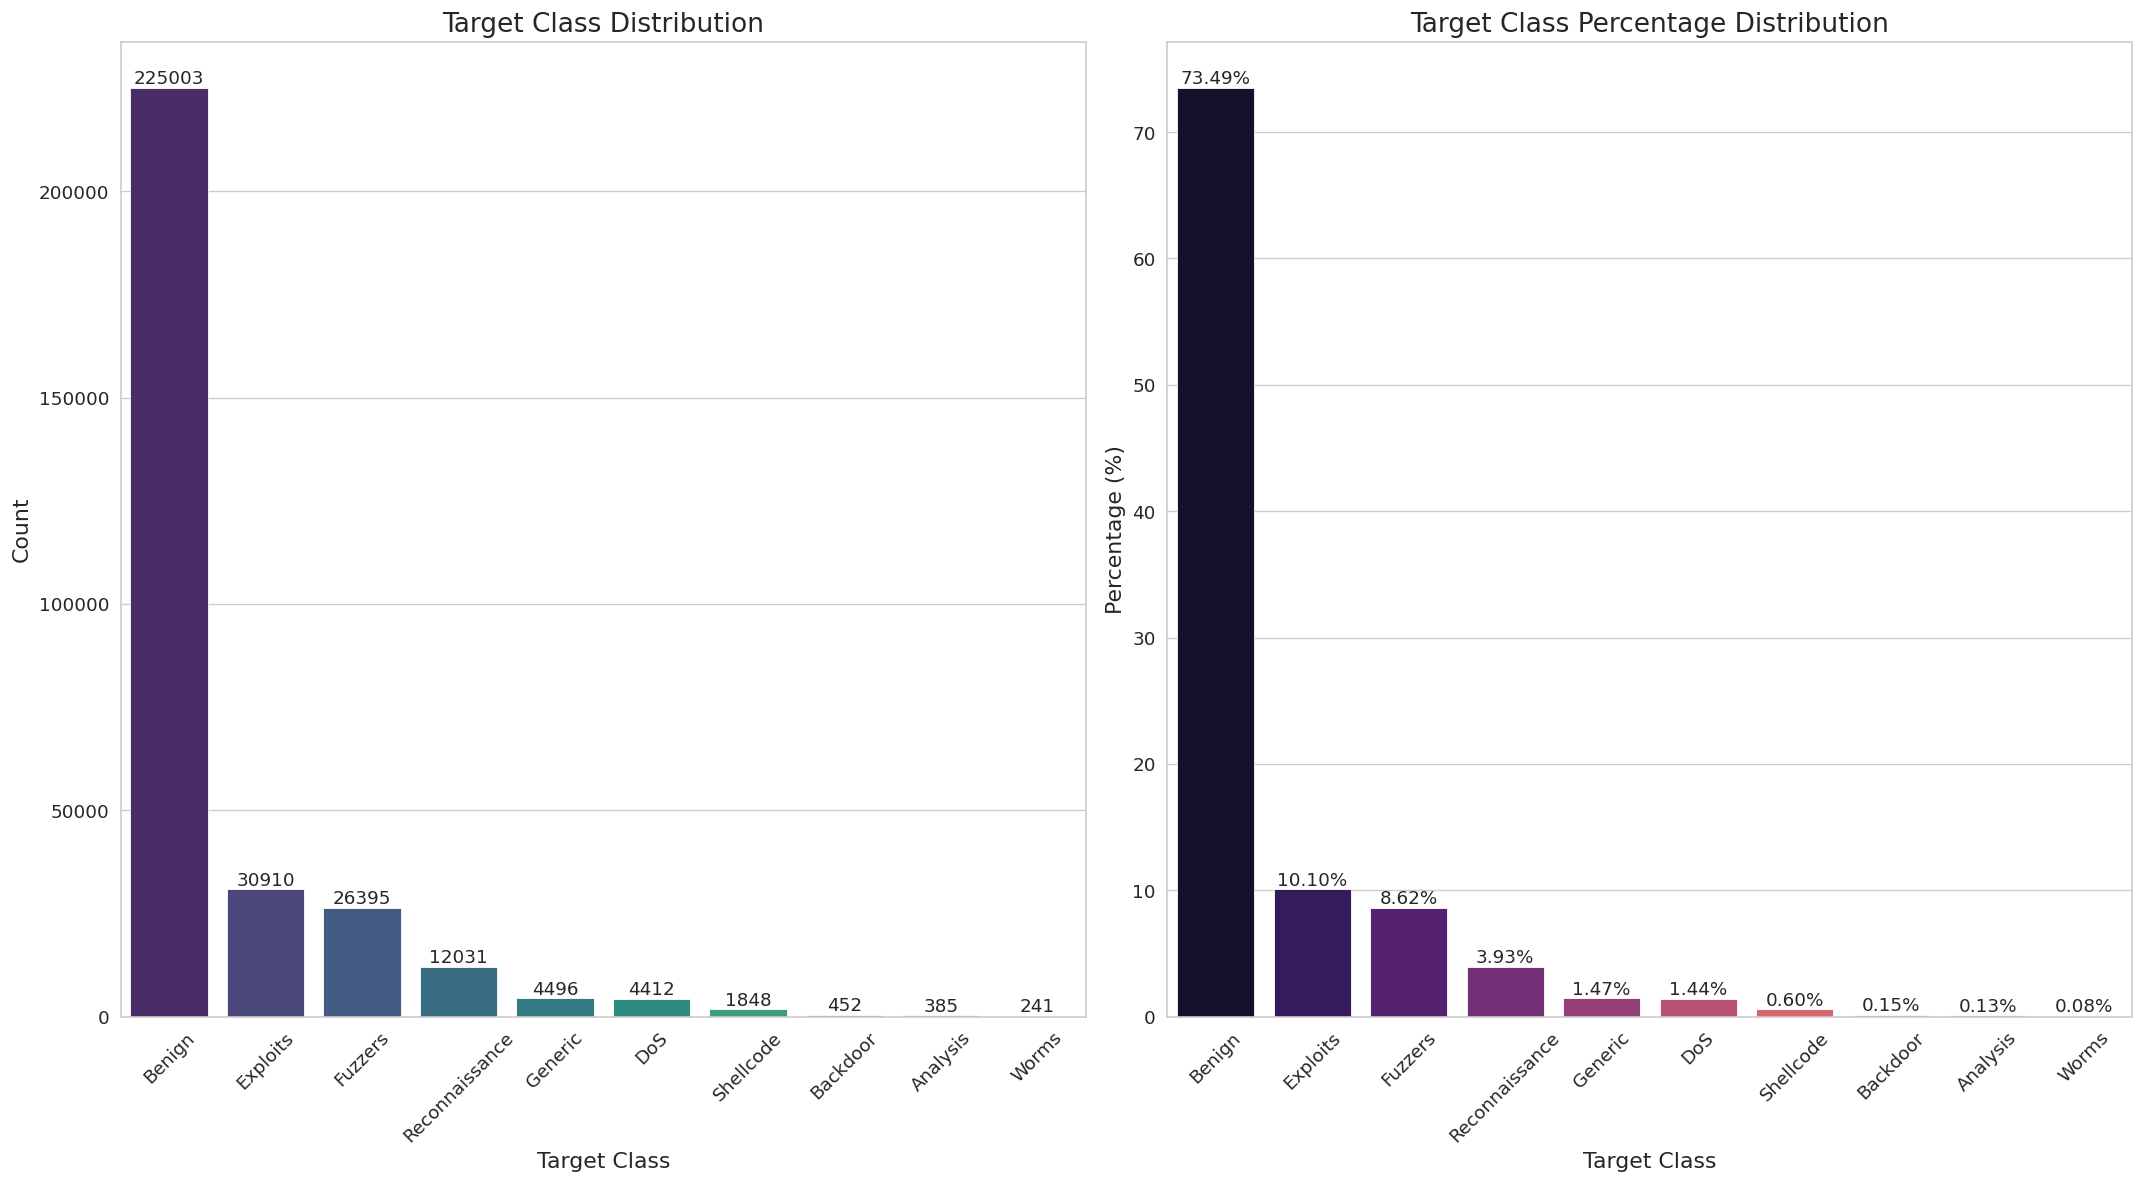

In [30]:
# Target class distribution: count and percentage
target_counts = df["Label_mapped"].value_counts()
target_percentages = df["Label_mapped"].value_counts(normalize=True).mul(100)

fig, axes = plt.subplots(1, 2, figsize=(18, 10))

# Count distribution
sns.barplot(
    x=target_counts.index,
    y=target_counts.values,
    ax=axes[0],
    palette="viridis"
)
axes[0].set_title("Target Class Distribution")
axes[0].set_xlabel("Target Class")
axes[0].set_ylabel("Count")
axes[0].tick_params(axis="x", rotation=45)

for container in axes[0].containers:
    axes[0].bar_label(container, fmt="%.0f")

# Percentage distribution
sns.barplot(
    x=target_percentages.index,
    y=target_percentages.values,
    ax=axes[1],
    palette="magma"
)
axes[1].set_title("Target Class Percentage Distribution")
axes[1].set_xlabel("Target Class")
axes[1].set_ylabel("Percentage (%)")
axes[1].tick_params(axis="x", rotation=45)

for container in axes[1].containers:
    axes[1].bar_label(container, fmt="%.2f%%")

plt.tight_layout()
plt.savefig("Target class Distribution.png")
plt.show()

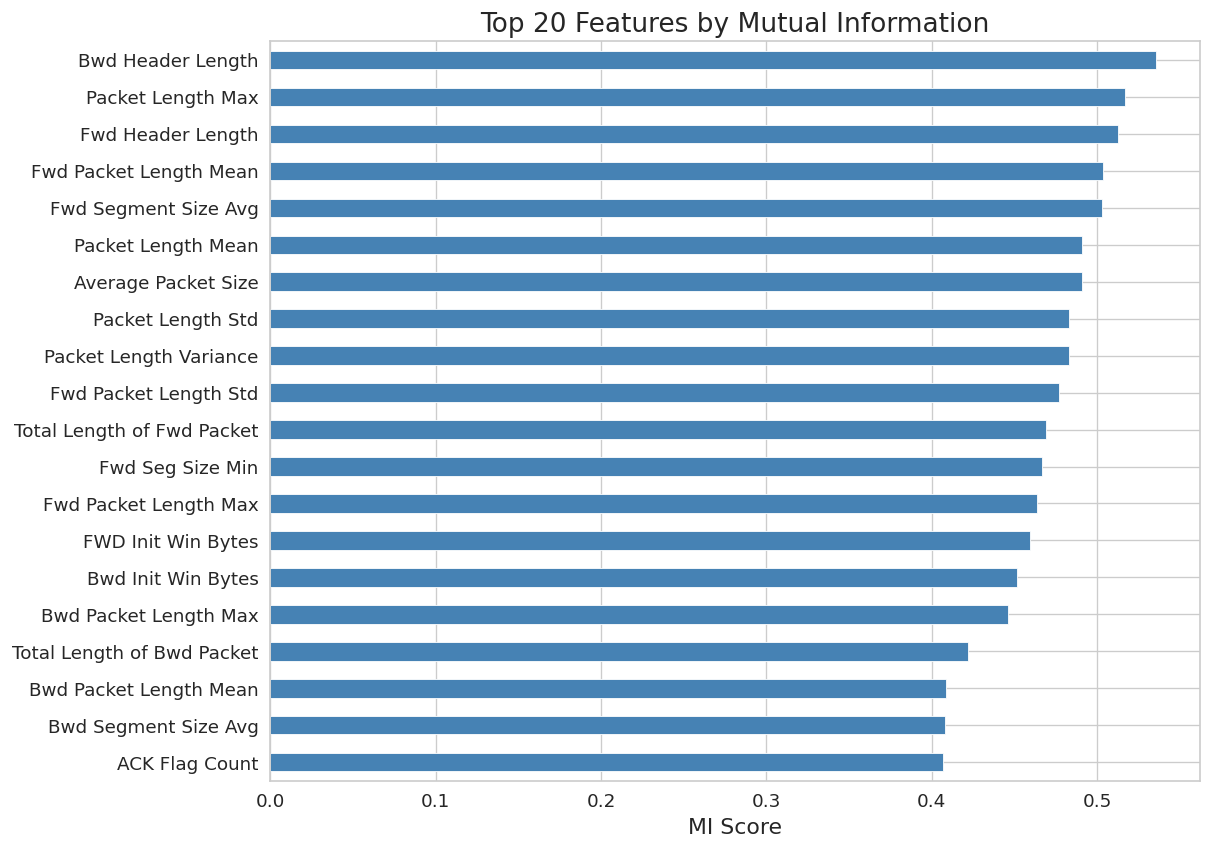

In [31]:
import warnings
warnings.filterwarnings('ignore')

# Checking for the top important features using Mutual Information


# Copy dataframe
temp_df = df.copy()


X_prime = temp_df.drop(columns=["Label","Label_mapped"])
y_prime = temp_df["Label"]

# Impute missing values in X_prime
# Using mean imputation as a simple strategy
for col in X_prime.columns:
    if X_prime[col].isnull().any():
        X_prime[col] = X_prime[col].fillna(X_prime[col].mean())

mi = mutual_info_classif(
    X_prime,
    y_prime,
    random_state=42
)

mi_scores = (
    pd.Series(mi, index=X_prime.columns)
      .sort_values(ascending=False)
)
# ploting the top 20 features by Mutual Information
plt.figure(figsize=(10,8))

mi_scores.head(20).sort_values().plot(kind="barh", color = "steelblue")

plt.title("Top 20 Features by Mutual Information")

plt.xlabel("MI Score")

plt.show()

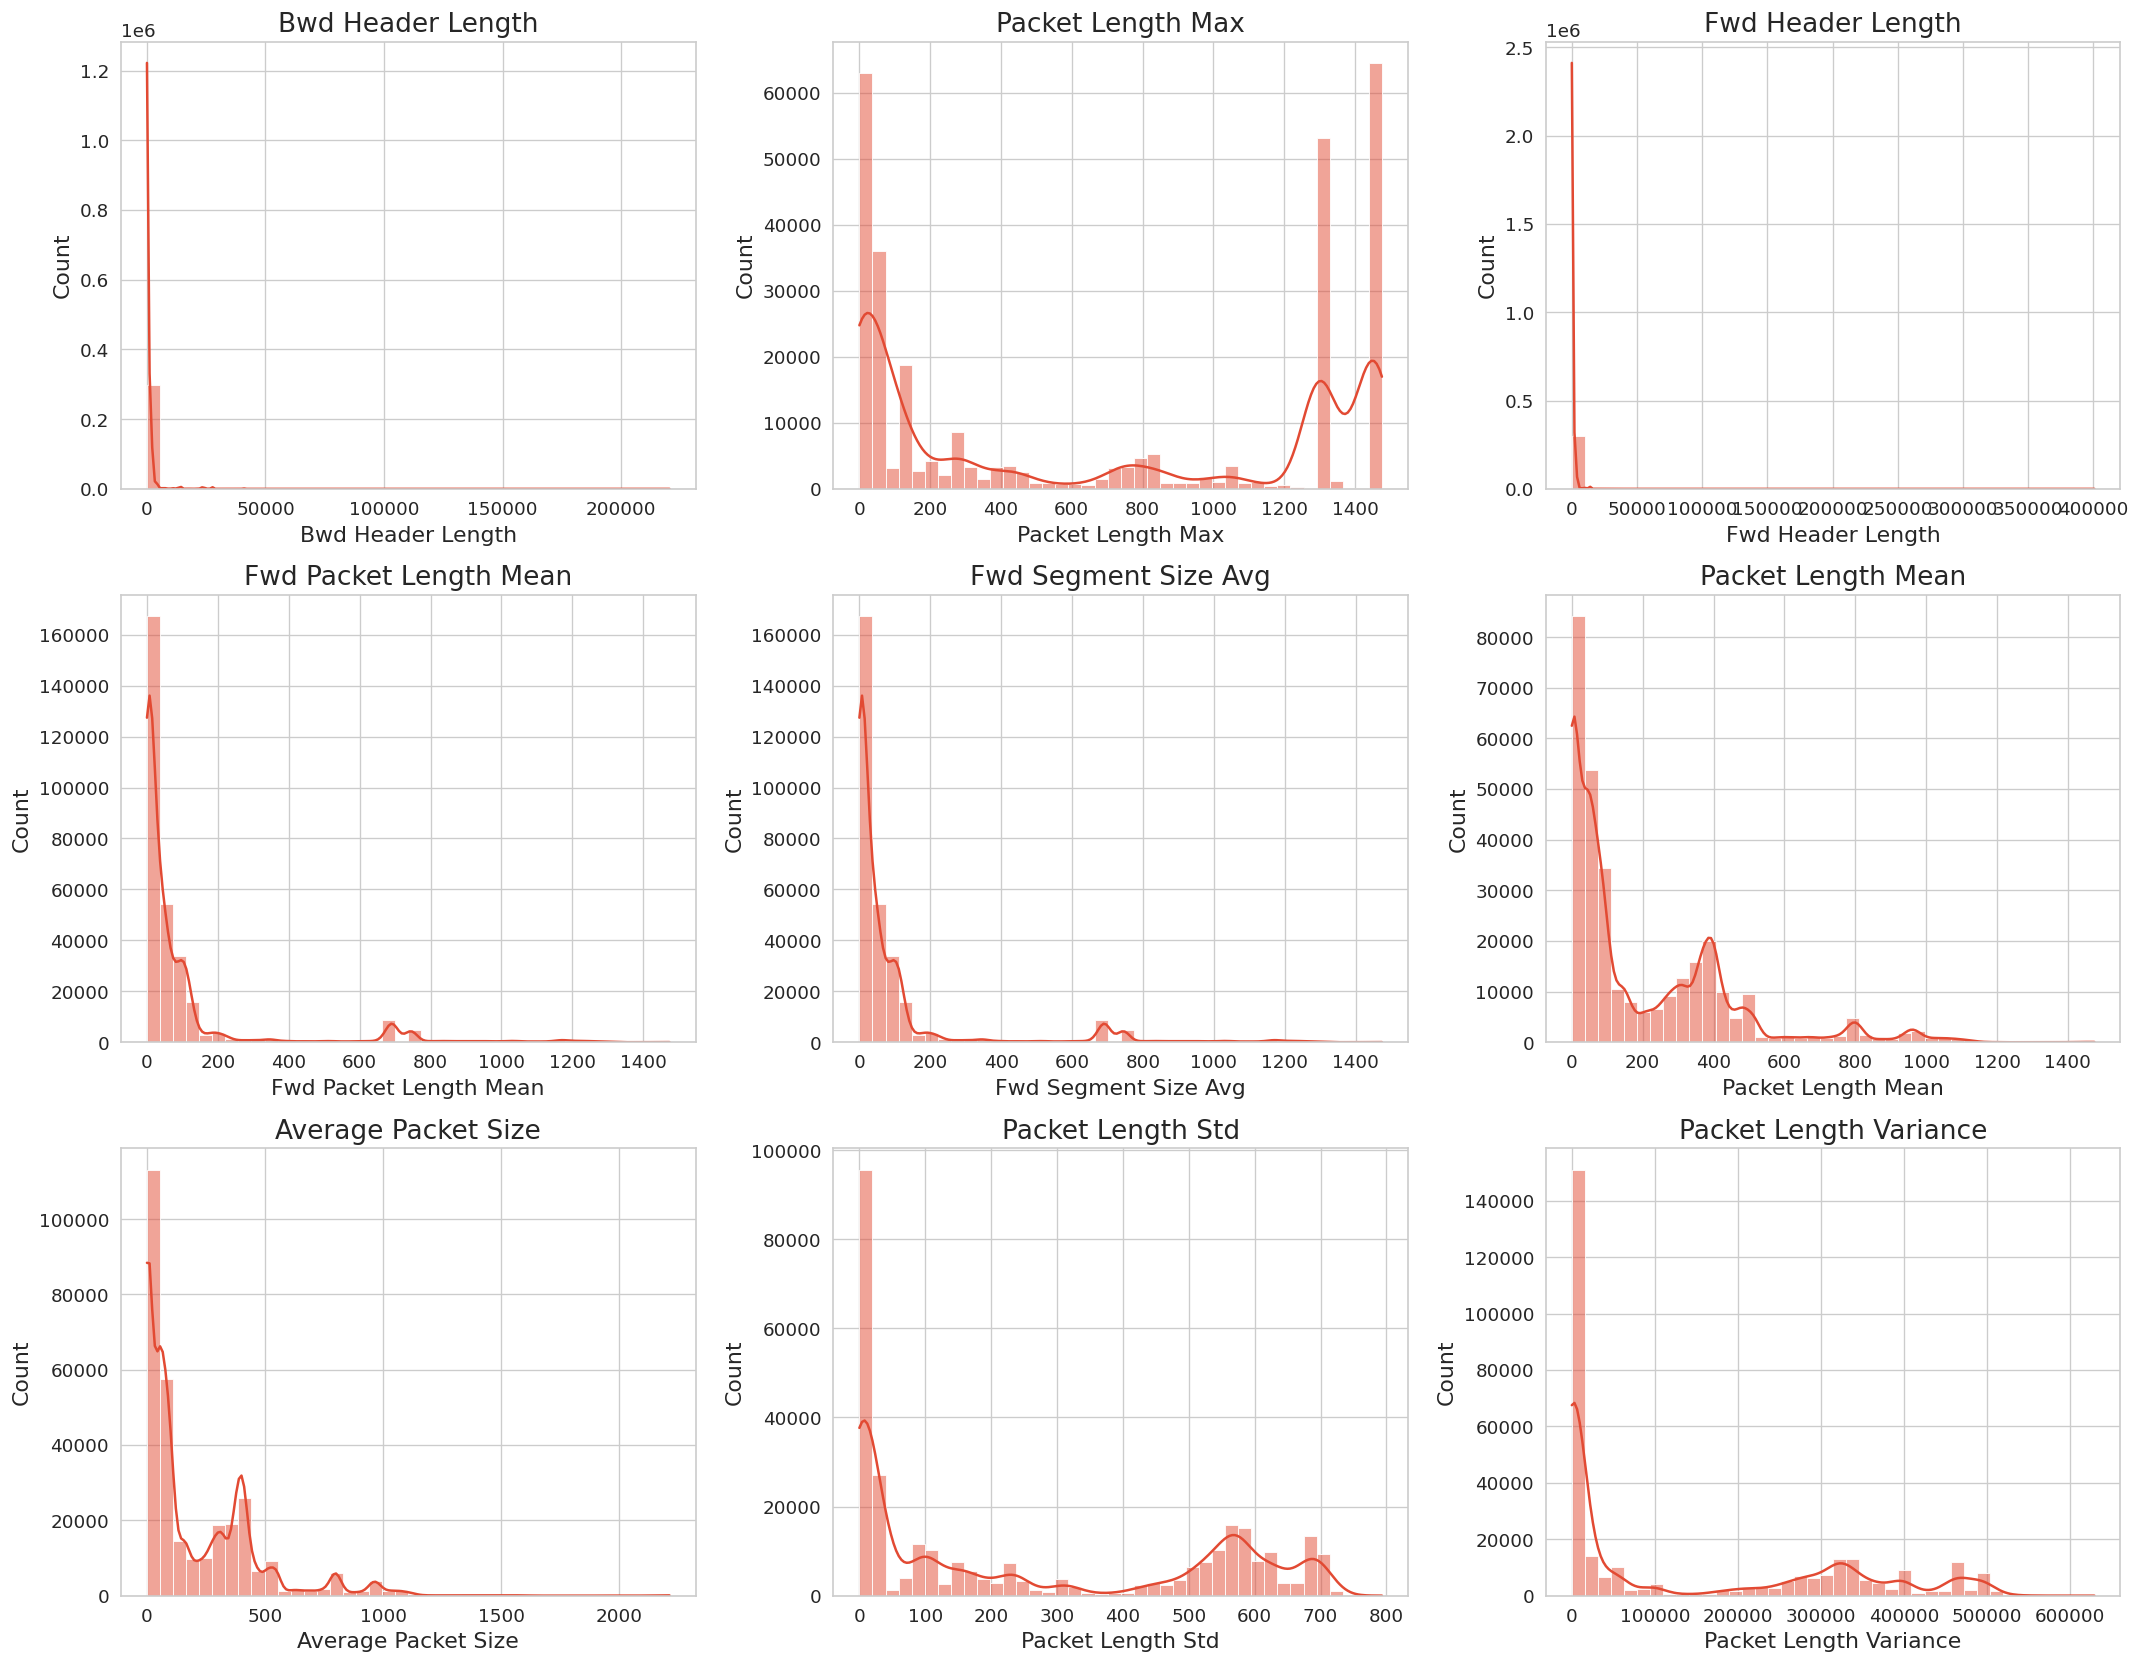

In [32]:
#Distribution of top important feature..
features = mi_scores.head(9).index.tolist()
fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for ax, col in zip(axes, features):
    sns.histplot(
        df[col],
        bins=40,
        kde=True,
        ax=ax
    )
    ax.set_title(col)

for ax in axes[len(features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig("Important Features distribution.png")
plt.show()

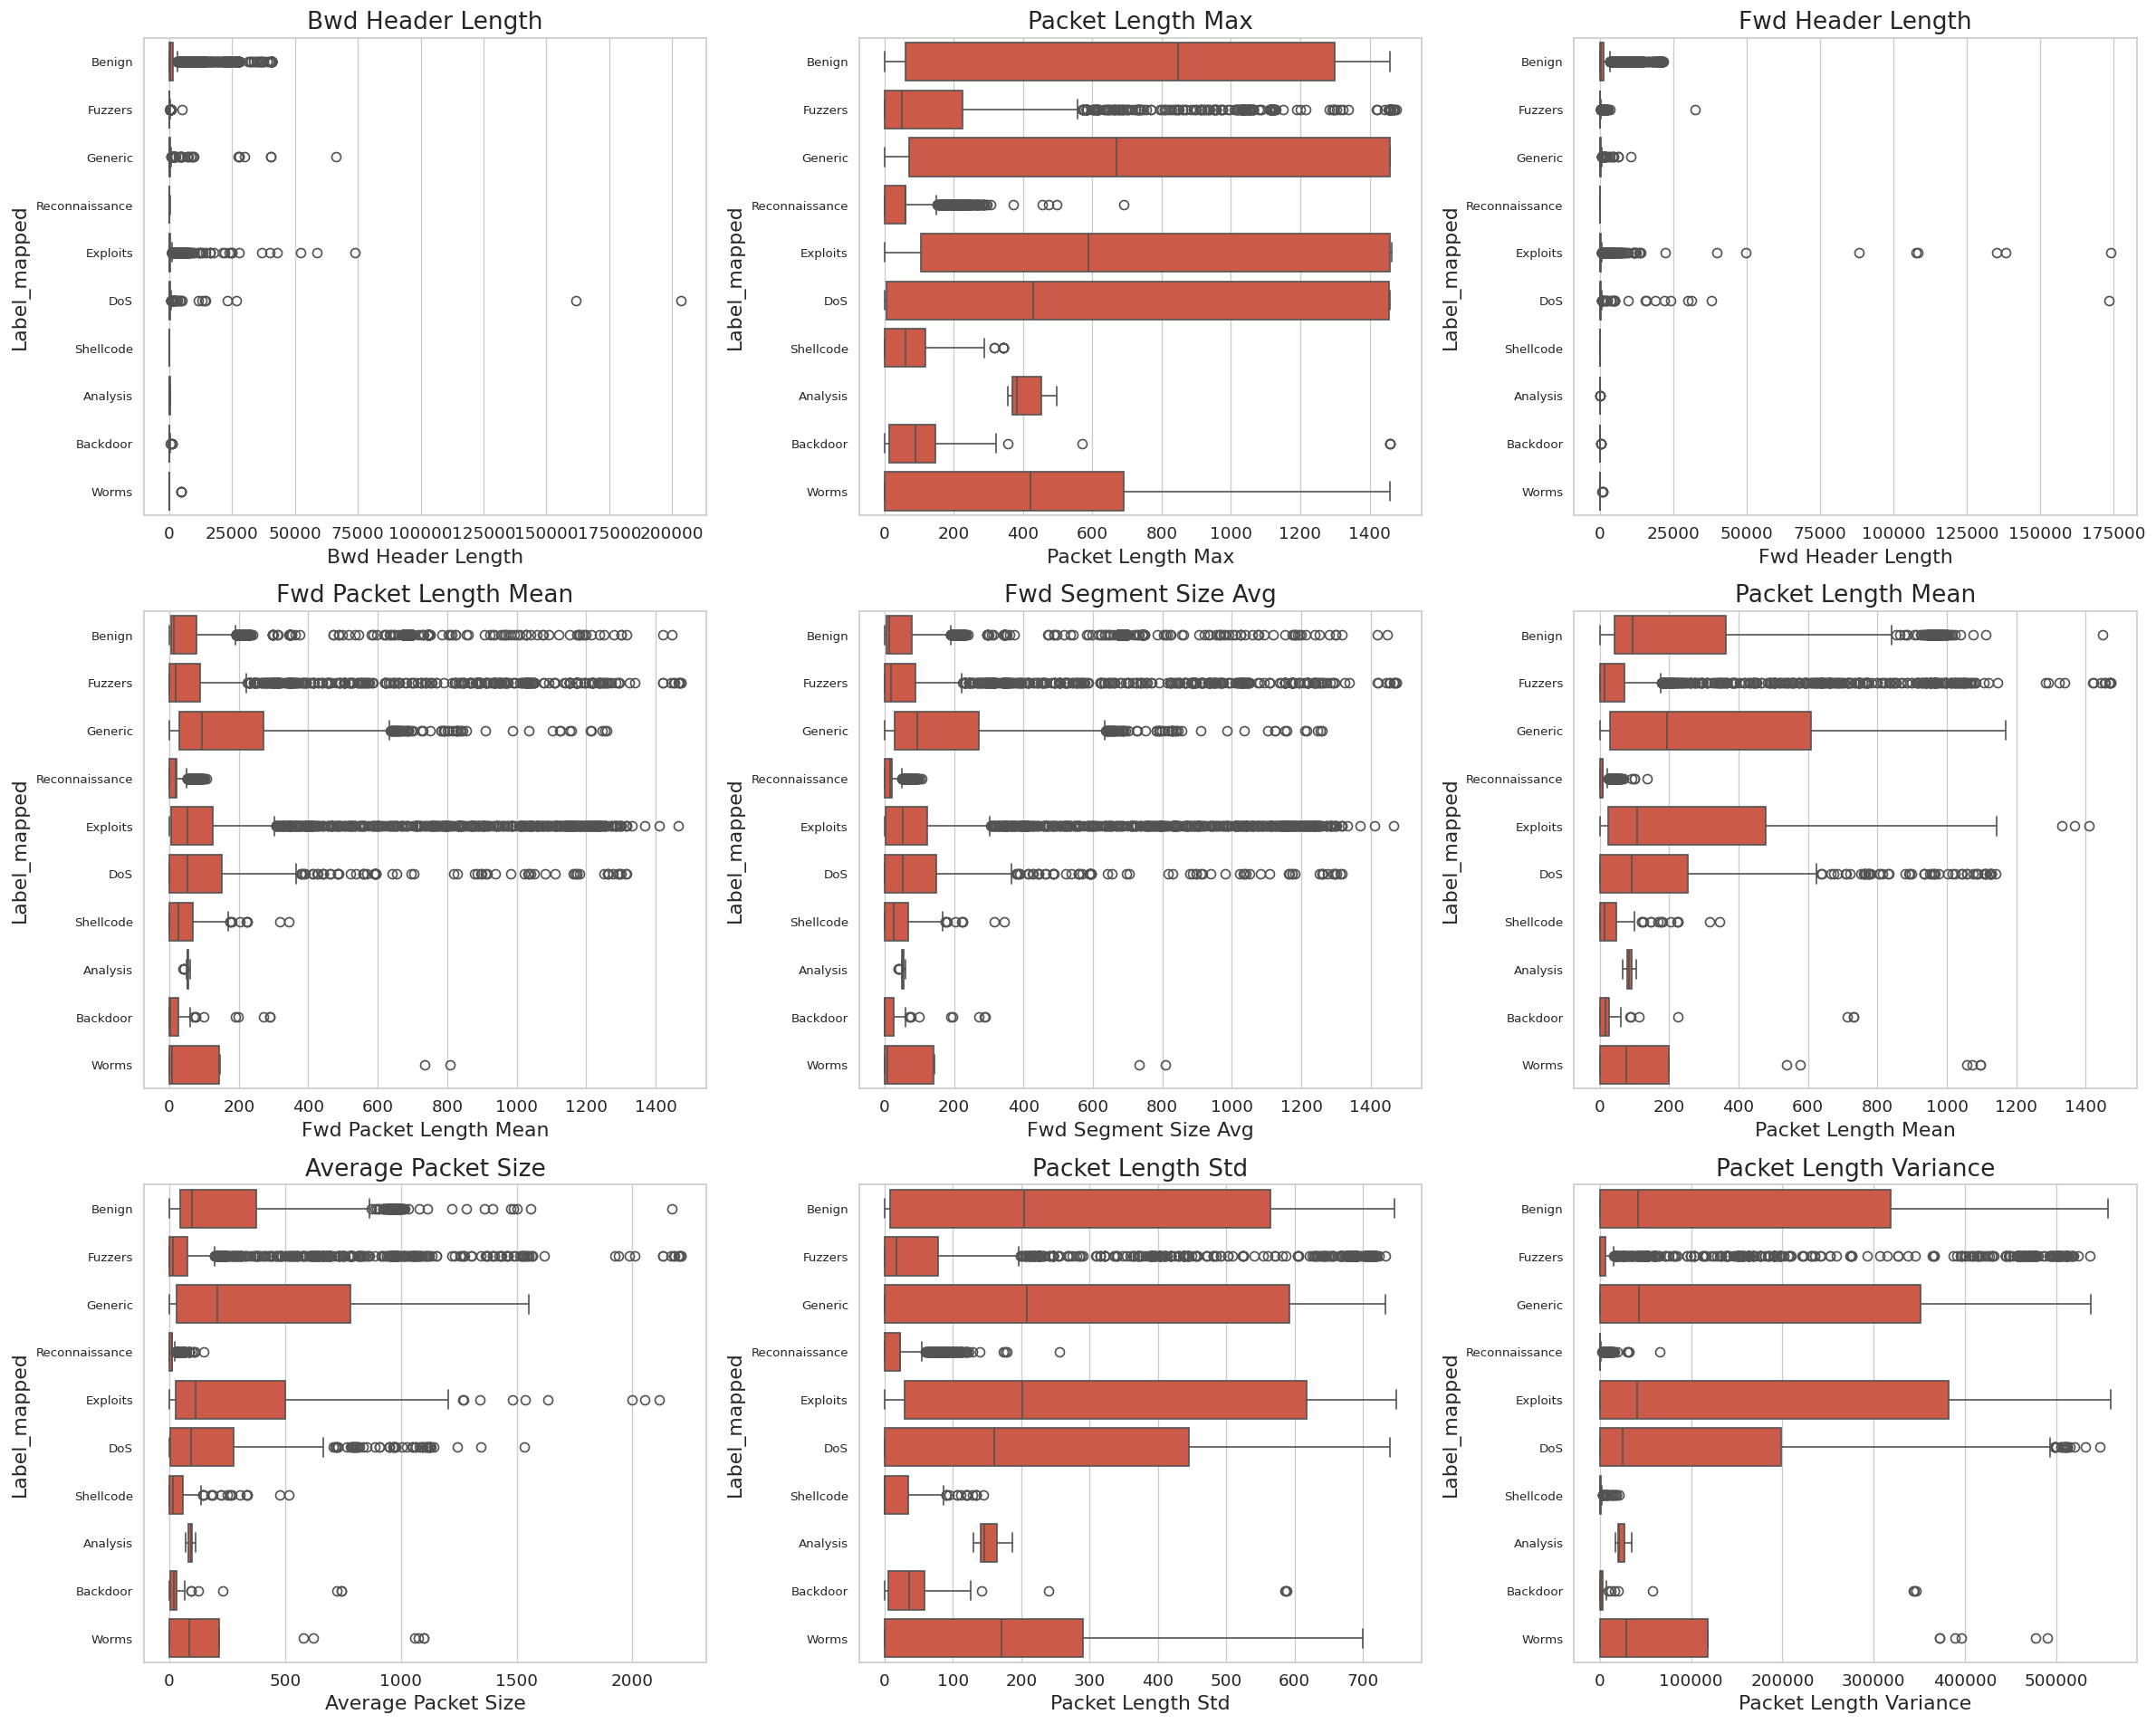

In [33]:
import warnings
warnings.filterwarnings('ignore')

# Target class vs important features......

# Sample a smaller portion of the data for visualization to optimize performance
# For example, sample 10% of the data. Adjust as needed.
df_sampled = df.sample(frac=0.1, random_state=SEED)

fig, axes = plt.subplots(3, 3, figsize=(20, 16))
axes = axes.flatten()

for ax, col in zip(axes, features):
    sns.boxplot(
        data=df_sampled, # Use the sampled DataFrame here
        x=col,
        y="Label_mapped", # Use 'Label_mapped' for better readability on y-axis
        ax=ax
    )
    ax.set_title(col)
    ax.tick_params(axis="y", labelsize=8)

for ax in axes[len(features):]:
    ax.set_visible(False)

plt.tight_layout()
plt.savefig("Target_class vs Important Features.png")
plt.show()

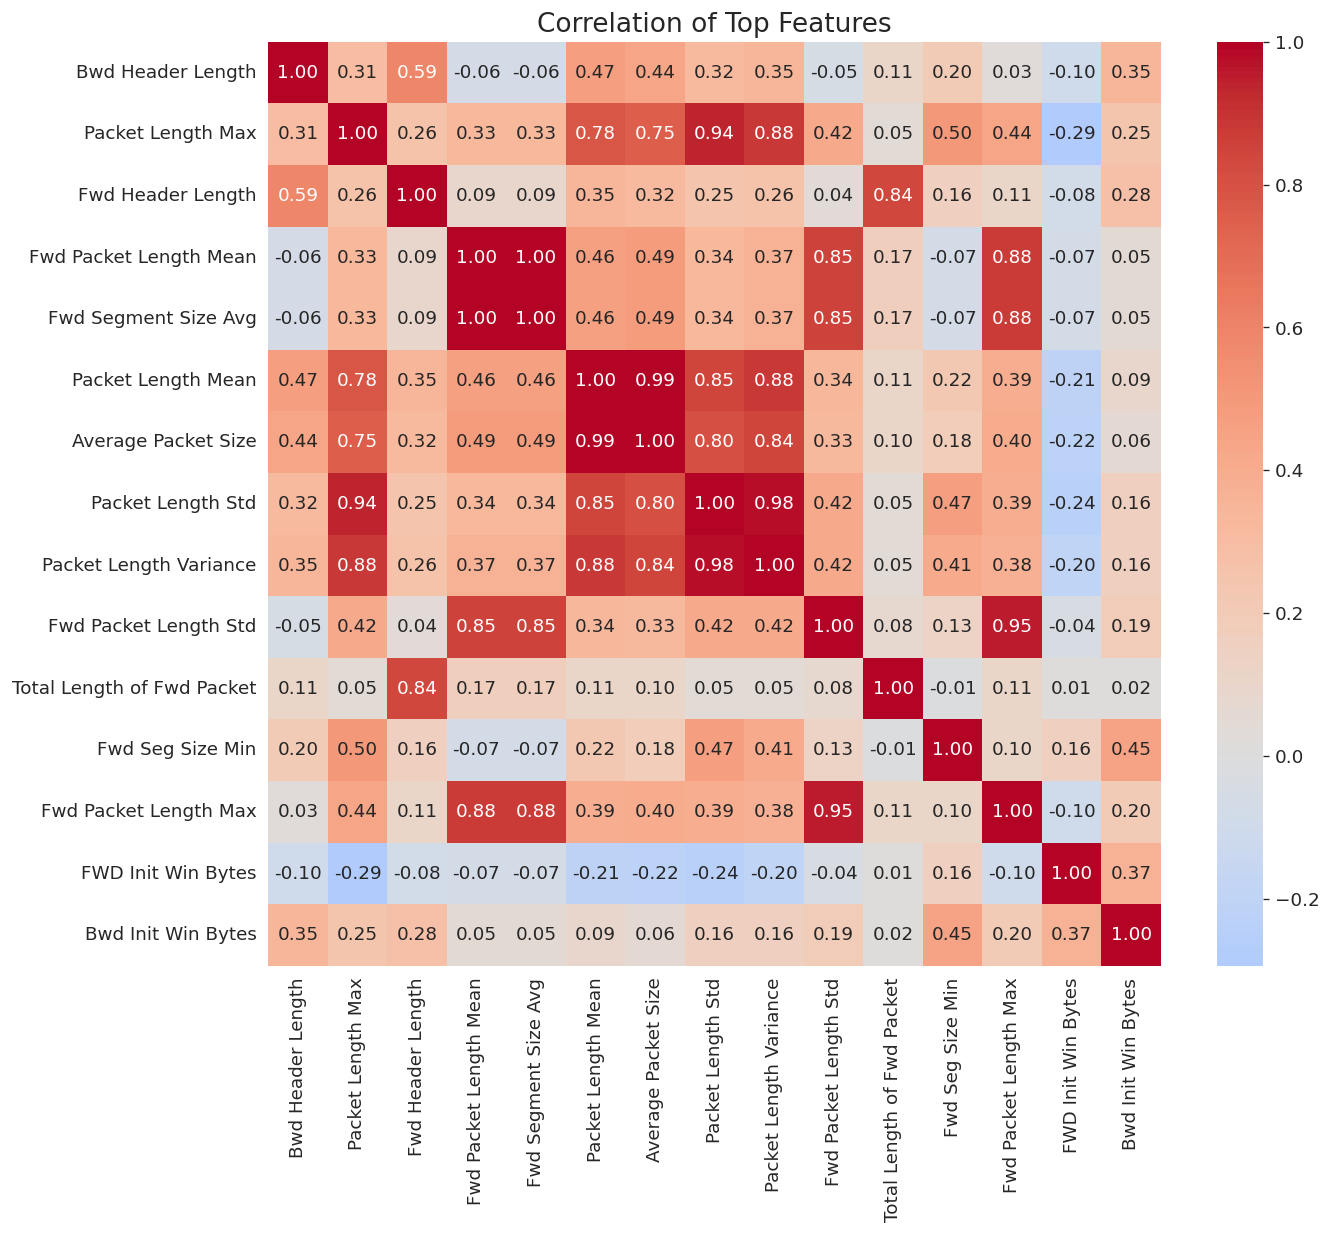

In [34]:
## Corelation among top features..
top_features = mi_scores.head(15).index

plt.figure(figsize=(12,10))

sns.heatmap(
    df[top_features].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Correlation of Top Features")
plt.savefig("Corelation Heatmap.jpeg")

plt.show()

In [35]:
threshold = 0.90
top_features = mi_scores.head(20).index.to_list()
corr_matrix = temp_df[top_features].corr().abs()

upper = corr_matrix.where(
    np.triu(np.ones(corr_matrix.shape), k=1).astype(bool)
)

high_corr = []

for column in upper.columns:
    for row in upper.index:
        value = upper.loc[row, column]

        if pd.notna(value) and value > threshold:
            mi_a = mi_scores.get(row, np.nan)
            mi_b = mi_scores.get(column, np.nan)
            mi_pair = np.nanmean([mi_a, mi_b])

            high_corr.append(
                [row, column, value, mi_pair]
            )

high_corr_df = pd.DataFrame(
    high_corr,
    columns=[
        "Feature A",
        "Feature B",
        "Correlation",
        "MI Score"
    ]
)

display(high_corr_df.sort_values("Correlation", ascending=False).reset_index(drop=True))

,Feature A,Feature B,Correlation,MI Score
0,Fwd Packet Length Mean,Fwd Segment Size Avg,1.000000,0.503317
1,Bwd Packet Length Mean,Bwd Segment Size Avg,1.000000,0.408163
2,Packet Length Mean,Average Packet Size,0.991194,0.490977
3,Packet Length Std,Packet Length Variance,0.976877,0.482960
4,Fwd Packet Length Std,Fwd Packet Length Max,0.954414,0.470427
5,Bwd Header Length,Total Length of Bwd Packet,0.945775,0.478783
6,Packet Length Max,Packet Length Std,0.943826,0.499939
7,Fwd Header Length,ACK Flag Count,0.917166,0.459840


In [36]:
# Now removing highly correlated features based on MI score and correlation threshold
redundant_features = [
    "Fwd Packet Length Mean",
    "Average Packet Size",
    "Total Fwd Packet",
    "Packet Length Variance",
    "Fwd Packet Length Std",
    "Total Length of Bwd Packet",
    "Packet Length Max",
    "Total Length of Fwd Packet",
    "ACK Flag Count"
]


print(f"Observation: Based on Mutual Information and correlation analysis, the following features appear redundant and are candidates for removal.: {redundant_features}")

Observation: Based on Mutual Information and correlation analysis, the following features appear redundant and are candidates for removal.: ['Fwd Packet Length Mean', 'Average Packet Size', 'Total Fwd Packet', 'Packet Length Variance', 'Fwd Packet Length Std', 'Total Length of Bwd Packet', 'Packet Length Max', 'Total Length of Fwd Packet', 'ACK Flag Count']


# Project 10 — CIC-UNSW-NB15 Augmented Dataset

## Objective

Develop an **imbalance-aware multiclass Network Intrusion Detection System (NIDS)** using machine learning, with particular focus on detecting rare attack classes.

## Dataset

**CIC-UNSW-NB15 Augmented Dataset**

* Features: **76**
* Classes: **10**
* Labels: **0–9**
* Label `0`: Benign
* Other classes represent different network attack categories.

## EDA Summary

The dataset contains significant **class imbalance**, with the Benign class representing approximately **80%** of the samples. Several attack classes are comparatively rare, making accuracy alone insufficient for evaluating model performance.

EDA also identified a substantial number of duplicate feature records and several groups of highly correlated features.

### Important Findings

* Severe class imbalance is present.
* Exact duplicate records exist.
* Some identical feature vectors appear with different labels, indicating **feature-space label collisions**.
* Multiple features show very high correlation (>90%).
* Mutual Information was also examined to understand feature–target relationships.
* No labels were arbitrarily changed based on feature collisions.

## Data Preparation Strategy

* Preserve the original numerical labels for modeling.
* Use label names only for visualization and interpretation.
* Remove exact duplicate records when appropriate.
* Retain feature vectors with conflicting labels rather than assuming they are mislabeled.
* Prevent identical feature groups from appearing across training and testing sets.
* Evaluate both the original and reduced feature sets during modeling.

## Modeling Plan

The project will compare multiple machine learning approaches, including:

* Logistic Regression
* Decision Tree
* Random Forest
* HistGradientBoosting
* XGBoost
* Additional imbalance-aware models where appropriate

## Evaluation

Because of the class imbalance, the primary evaluation metrics will be:

* **Macro Precision**
* **Macro Recall**
* **Macro F1-score**
* Per-class Precision, Recall and F1
* Confusion Matrix
* Weighted F1
* Accuracy as a secondary metric

## Research Focus

**How effectively can machine learning models classify benign traffic and multiple network intrusion classes under severe class imbalance, particularly for rare attack categories?**

The main goal is not simply to maximize accuracy, but to determine how well the models detect **minority and rare intrusion classes** without data leakage.
